# APS – Análise de desempenho de algoritmos de ordenação (dados de desmatamento da Amazônia – INPE/TerraBrasilis)

**Antes de rodar:** coloque os dois CSVs na mesma pasta deste notebook e confira os nomes na célula de configuração.

Ordem de uso:
1. Rode a célula de configuração e as de funções/algoritmos.
2. Faça primeiro um teste rápido com `AMOSTRA = 5000` (célula de configuração).
3. Para o experimento final, coloque `AMOSTRA = None` e rode as bases (a base completa pode levar horas nos algoritmos O(n²)).

In [1]:
import time
import random
import pandas as pd
import matplotlib.pyplot as plt

# ================= CONFIGURAÇÃO =================
ARQUIVO_COM_FILTRO = "deter-amz-daily-20-10-2026-09_28_15.csv"
ARQUIVO_SEM_FILTRO = "deter-amz-daily-20-10-2026-09_28_18.csv"

DATA_INICIAL = "2021-08-20"
DATA_FINAL   = "2025-08-20"

# None = usa todos os registros (experimento final).
# Número (ex.: 5000) = usa uma amostra, só para testar rápido.
AMOSTRA = None

SEMENTE = 42   # garante que o embaralhamento seja reproduzível
# =================================================

In [2]:
def carregar_dados(caminho):
    """Lê o CSV, recorta o período da APS e devolve o DataFrame e a lista de valores de areaMunKm."""
    df = pd.read_csv(caminho, encoding="utf-8-sig")

    coluna = next(c for c in df.columns if str(c).strip().lower() == "areamunkm")

    df["viewDate"] = pd.to_datetime(df["viewDate"], format="%d/%m/%Y")
    df = df[(df["viewDate"] >= DATA_INICIAL) & (df["viewDate"] <= DATA_FINAL)]

    if AMOSTRA is not None and AMOSTRA < len(df):
        df = df.sample(n=AMOSTRA, random_state=SEMENTE)

    valores = df[coluna].tolist()
    return df, valores


def montar_cenarios(valores):
    """Cenário 1: inversamente ordenado (decrescente). Cenário 2: aleatório."""
    inverso = sorted(valores, reverse=True)

    aleatorio = valores.copy()
    random.seed(SEMENTE)
    random.shuffle(aleatorio)

    return inverso, aleatorio

## Algoritmos de ordenação
Todos ordenam de forma **crescente** pelo campo `areaMunKm` e trabalham sobre uma cópia da lista.

In [3]:
def bubble_sort(dados):
    dados = dados.copy()
    n = len(dados)
    for i in range(n - 1):
        for j in range(n - 1 - i):
            if dados[j] > dados[j + 1]:
                dados[j], dados[j + 1] = dados[j + 1], dados[j]
    return dados


def selection_sort(dados):
    dados = dados.copy()
    n = len(dados)
    for i in range(n - 1):
        menor = i
        for j in range(i + 1, n):
            if dados[j] < dados[menor]:
                menor = j
        dados[i], dados[menor] = dados[menor], dados[i]
    return dados


def insertion_sort(dados):
    dados = dados.copy()
    for i in range(1, len(dados)):
        atual = dados[i]
        j = i - 1
        while j >= 0 and dados[j] > atual:
            dados[j + 1] = dados[j]
            j -= 1
        dados[j + 1] = atual
    return dados


def merge_sort(dados):
    if len(dados) <= 1:
        return dados.copy()
    meio = len(dados) // 2
    esquerda = merge_sort(dados[:meio])
    direita = merge_sort(dados[meio:])

    resultado = []
    i = j = 0
    while i < len(esquerda) and j < len(direita):
        if esquerda[i] <= direita[j]:
            resultado.append(esquerda[i])
            i += 1
        else:
            resultado.append(direita[j])
            j += 1
    resultado.extend(esquerda[i:])
    resultado.extend(direita[j:])
    return resultado


def quick_sort(dados):
    if len(dados) <= 1:
        return dados.copy()
    pivo = dados[len(dados) // 2]
    menores = [x for x in dados if x < pivo]
    iguais  = [x for x in dados if x == pivo]
    maiores = [x for x in dados if x > pivo]
    return quick_sort(menores) + iguais + quick_sort(maiores)


ALGORITMOS = [
    ("Bubble Sort", bubble_sort),
    ("Selection Sort", selection_sort),
    ("Insertion Sort", insertion_sort),
    ("Merge Sort", merge_sort),
    ("Quick Sort", quick_sort),
]

## Experimento
Para cada algoritmo, mede o tempo nos dois cenários (inversamente ordenado e aleatório) e confere se o resultado realmente saiu ordenado.

In [4]:
def medir(algoritmo, dados):
    inicio = time.perf_counter()
    resultado = algoritmo(dados)
    fim = time.perf_counter()
    assert resultado == sorted(dados), "O algoritmo não ordenou corretamente!"
    return fim - inicio


def executar_experimento(nome_base, caminho):
    df, valores = carregar_dados(caminho)
    inverso, aleatorio = montar_cenarios(valores)

    print(f"=== {nome_base} ===")
    print(f"Registros no período {DATA_INICIAL} a {DATA_FINAL}: {len(valores):,}".replace(",", "."))
    print("Visualização parcial:")
    display(df.head())

    linhas = []
    for nome, funcao in ALGORITMOS:
        print(f"Rodando {nome}...", flush=True)
        t_inverso = medir(funcao, inverso)
        t_aleatorio = medir(funcao, aleatorio)
        linhas.append([nome, t_inverso, t_aleatorio])
        print(f"  Inversamente ordenada: {t_inverso:.4e} s | Aleatória: {t_aleatorio:.4e} s", flush=True)

    tabela = pd.DataFrame(linhas, columns=["Algoritmo", "Inversamente ordenada", "Aleatória"])
    tabela.insert(0, "Base", nome_base)
    tabela["Registros"] = len(valores)

    # salva logo após terminar, para não perder o resultado
    nome_arquivo = "resultados_" + nome_base.lower().replace(" ", "_") + ".csv"
    tabela.to_csv(nome_arquivo, index=False)
    print(f"Resultados salvos em {nome_arquivo}")
    return tabela

### Base COM filtros

In [5]:
resultado_com_filtro = executar_experimento("Com filtro", ARQUIVO_COM_FILTRO)
resultado_com_filtro

=== Com filtro ===
Registros no período 2021-08-20 a 2025-08-20: 109.978
Visualização parcial:


,viewDate,areaMunKm,areaUcKm,uc,uf,municipio,geocod,className
0,2024-10-06,0.07,0.00,NaN,AP,Pedra Branca do Amapari,1600154,MINERACAO
1,2024-08-29,0.12,0.12,ÁREA DE PROTEÇÃO AMBIENTAL DO TAPAJÓS,PA,Jacareacanga,1503754,MINERACAO
2,2023-04-10,0.11,0.00,NaN,RR,Alto Alegre,1400050,MINERACAO
3,2021-10-03,0.01,0.00,NaN,PA,Jacareacanga,1503754,MINERACAO
4,2021-10-03,0.09,0.00,NaN,PA,Jacareacanga,1503754,MINERACAO


Rodando Bubble Sort...
  Inversamente ordenada: 1.8424e+03 s | Aleatória: 1.2879e+03 s
Rodando Selection Sort...
  Inversamente ordenada: 6.4988e+02 s | Aleatória: 8.5374e+02 s
Rodando Insertion Sort...
  Inversamente ordenada: 1.1259e+03 s | Aleatória: 4.7804e+02 s
Rodando Merge Sort...
  Inversamente ordenada: 3.2271e-01 s | Aleatória: 4.7358e-01 s
Rodando Quick Sort...
  Inversamente ordenada: 6.8856e-02 s | Aleatória: 8.7263e-02 s
Resultados salvos em resultados_com_filtro.csv


,Base,Algoritmo,Inversamente ordenada,Aleatória,Registros
0,Com filtro,Bubble Sort,1842.430750,1287.896271,109978
1,Com filtro,Selection Sort,649.876806,853.742865,109978
2,Com filtro,Insertion Sort,1125.890682,478.041958,109978
3,Com filtro,Merge Sort,0.322706,0.473581,109978
4,Com filtro,Quick Sort,0.068856,0.087263,109978


### Base SEM filtros (recortada no período 2021–2025)

In [6]:
resultado_sem_filtro = executar_experimento("Sem filtro", ARQUIVO_SEM_FILTRO)
resultado_sem_filtro

=== Sem filtro ===
Registros no período 2021-08-20 a 2025-08-20: 206.988
Visualização parcial:


,viewDate,areaMunKm,areaUcKm,uc,uf,municipio,geocod,className
0,2025-08-01,0.07,0.0,NaN,AC,Feijo,1200302,DESMATAMENTO_CR
2,2023-09-29,0.35,0.0,NaN,RR,Amajari,1400027,DESMATAMENTO_CR
3,2024-09-03,0.11,0.0,NaN,RR,Normandia,1400407,DEGRADACAO
5,2021-09-22,0.35,0.0,NaN,PA,Trairao,1508050,DESMATAMENTO_CR
6,2022-09-24,0.07,0.0,NaN,MT,Peixoto de Azevedo,5106422,CICATRIZ_DE_QUEIMADA


Rodando Bubble Sort...
  Inversamente ordenada: 5.9064e+03 s | Aleatória: 3.2531e+03 s
Rodando Selection Sort...
  Inversamente ordenada: 1.5401e+03 s | Aleatória: 1.8037e+03 s
Rodando Insertion Sort...
  Inversamente ordenada: 2.8058e+03 s | Aleatória: 1.4593e+03 s
Rodando Merge Sort...
  Inversamente ordenada: 3.8204e-01 s | Aleatória: 5.9337e-01 s
Rodando Quick Sort...
  Inversamente ordenada: 1.1393e-01 s | Aleatória: 1.5262e-01 s
Resultados salvos em resultados_sem_filtro.csv


,Base,Algoritmo,Inversamente ordenada,Aleatória,Registros
0,Sem filtro,Bubble Sort,5906.377871,3253.076933,206988
1,Sem filtro,Selection Sort,1540.063707,1803.691255,206988
2,Sem filtro,Insertion Sort,2805.769797,1459.286876,206988
3,Sem filtro,Merge Sort,0.382041,0.593371,206988
4,Sem filtro,Quick Sort,0.113932,0.152617,206988


## Gráficos
Escala logarítmica no eixo Y, porque a diferença entre os algoritmos O(n²) e O(n log n) é de várias ordens de grandeza.

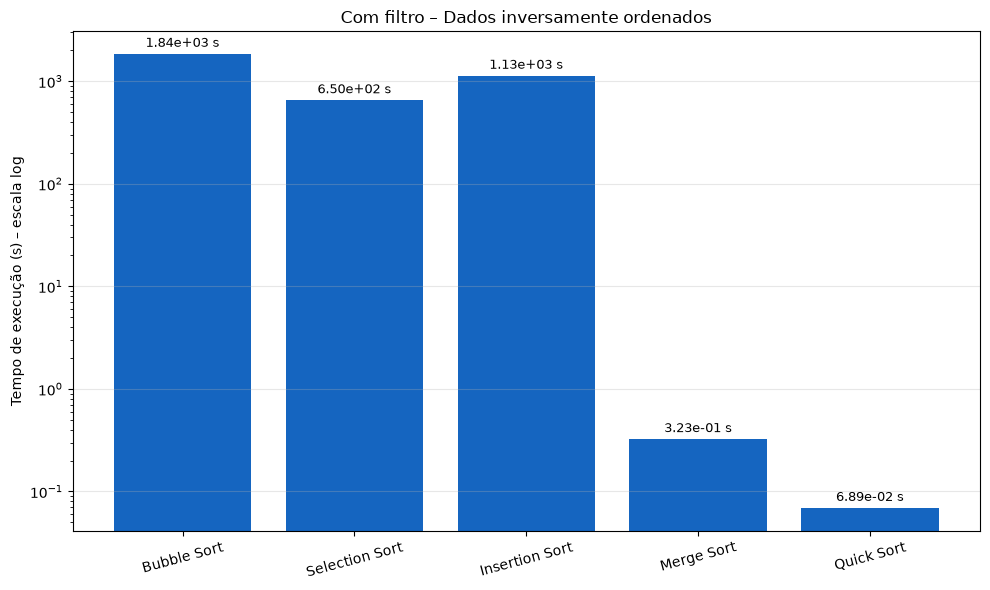

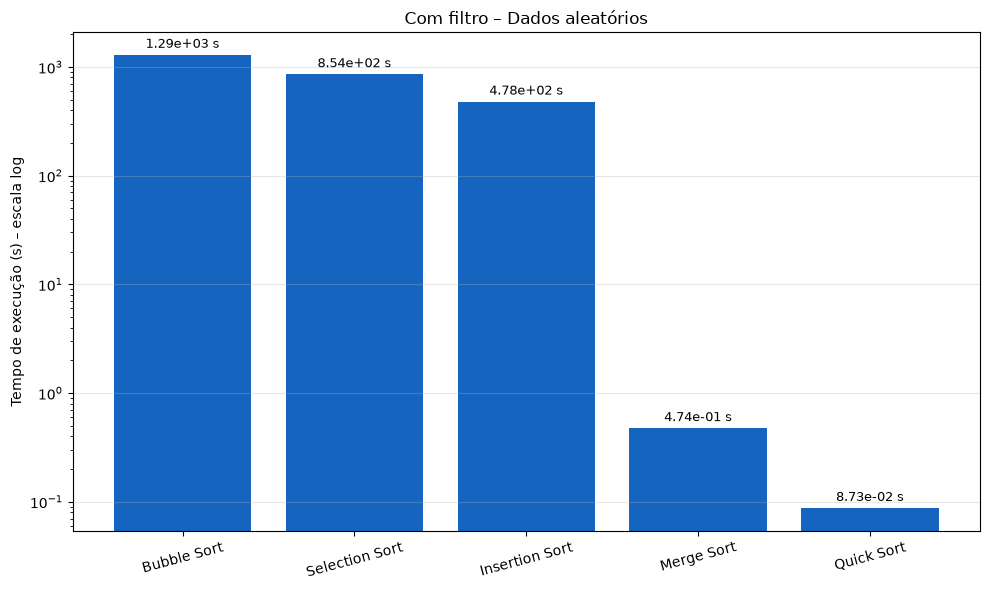

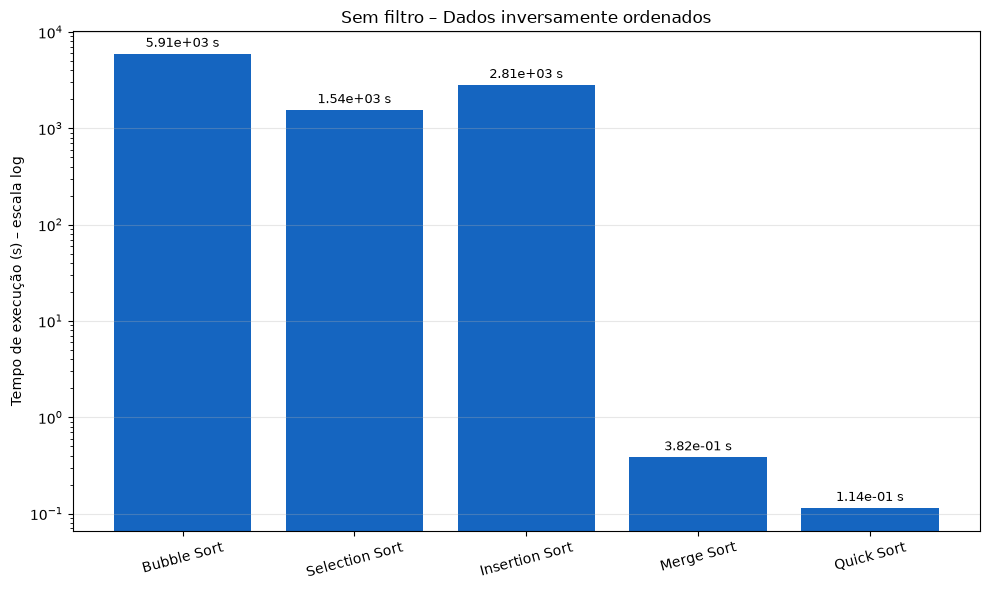

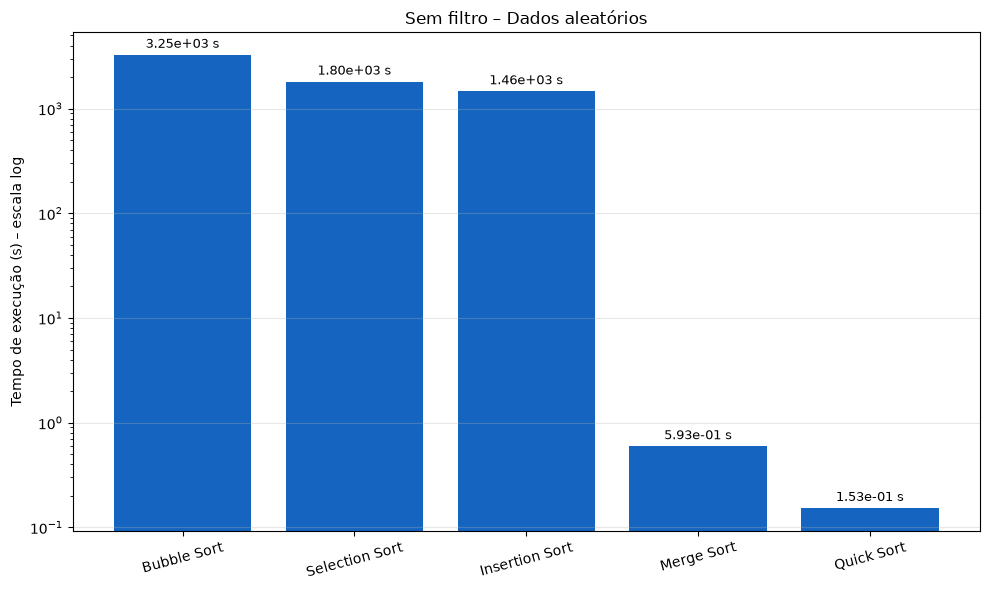

In [7]:
def grafico(tabela, coluna_tempo, titulo):
    fig, ax = plt.subplots(figsize=(10, 6))
    barras = ax.bar(tabela["Algoritmo"], tabela[coluna_tempo], color="#1565C0")
    ax.set_yscale("log")
    ax.set_ylabel("Tempo de execução (s) – escala log")
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0.3)
    for barra, tempo in zip(barras, tabela[coluna_tempo]):
        ax.annotate(f"{tempo:.2e} s", (barra.get_x() + barra.get_width() / 2, tempo),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
    plt.xticks(rotation=15)
    plt.tight_layout()
    arquivo = titulo.lower().replace(" ", "_").replace("–", "").replace("__", "_") + ".png"
    plt.savefig(arquivo, dpi=150)
    plt.show()


for nome, tabela in [("Com filtro", resultado_com_filtro), ("Sem filtro", resultado_sem_filtro)]:
    grafico(tabela, "Inversamente ordenada", f"{nome} – Dados inversamente ordenados")
    grafico(tabela, "Aleatória", f"{nome} – Dados aleatórios")

## Tabela final com os 20 tempos (10 por base)

In [8]:
tabela_final = pd.concat([resultado_com_filtro, resultado_sem_filtro], ignore_index=True)
tabela_final.to_csv("resultados_finais.csv", index=False)
tabela_final

,Base,Algoritmo,Inversamente ordenada,Aleatória,Registros
0,Com filtro,Bubble Sort,1842.430750,1287.896271,109978
1,Com filtro,Selection Sort,649.876806,853.742865,109978
2,Com filtro,Insertion Sort,1125.890682,478.041958,109978
3,Com filtro,Merge Sort,0.322706,0.473581,109978
4,Com filtro,Quick Sort,0.068856,0.087263,109978
5,Sem filtro,Bubble Sort,5906.377871,3253.076933,206988
6,Sem filtro,Selection Sort,1540.063707,1803.691255,206988
7,Sem filtro,Insertion Sort,2805.769797,1459.286876,206988
8,Sem filtro,Merge Sort,0.382041,0.593371,206988
9,Sem filtro,Quick Sort,0.113932,0.152617,206988
